# 07 — What synchronisation costs on the H100: CTA barriers, fences, the cluster barrier, mbarriers, flags and the grid barrier

**Goal.** Measure, on one H100 NVL at a locked 1635 MHz SM clock, the isolated cost in SM cycles of the synchronisation primitives that work *inside one kernel*:
- CTA barriers (`bar.sync`, named barriers, `bar.arrive`, `__syncwarp`) and `nanosleep`;
- memory fences at CTA, cluster and GPU scope, and the async-proxy fences;
- the two halves of the cluster barrier;
- the mbarrier operations, local and remote;
- thirteen ways for one CTA to tell another in the same cluster that data are ready;
- the grid-wide barrier of a cooperative launch.

For each primitive the notebook asks three questions: how long it takes, how the time grows with cluster size and thread count, and which hardware stall absorbs the waiting. Later protocol measurements (DSMEM transfers, TMA pipelines, cluster collectives) are split into data movement and synchronisation with these numbers. The ranking of signalling methods says which hand-off a cluster algorithm should use.

**Not covered here:**
- synchronisation between kernels: stream order, events, host-side synchronisation, programmatic dependent launch;
- the completion groups of asynchronous copies (`cp.async` and bulk `commit_group` / `wait_group`);
- warpgroup (`wgmma`) fences and `fence.proxy.tensormap`;
- system-scope fences;
- barriers with a reduction (`bar.red`) and `__syncwarp` with partial masks in divergent code;
- locks built from global atomics, and contention when many CTAs synchronise at the same time (every test here runs one CTA, one cluster or one grid in isolation).

## 2. Background

**Why synchronisation costs matter here.** Every protocol that moves data between thread blocks (CTAs) on the H100 — a DSMEM push between the CTAs of a cluster, a TMA bulk copy, a reduction across a cluster — consists of a data transfer *and* a signal that tells the consumer the data is complete and visible. When the transfers are small, the signal dominates. This notebook measures the signal side in isolation, so that later protocol measurements can be split into "data movement" and "synchronisation".

**Scopes and proxies.** The PTX memory model orders memory operations within a *scope*: `.cta` (one thread block) ⊂ `.cluster` (the CTAs of a thread-block cluster, which share their shared memories through DSMEM) ⊂ `.gpu` ⊂ `.sys`. A *release* operation makes the issuing thread's earlier writes visible to any thread that later *acquires* the released location (or barrier) at a scope that contains both. Fences (`fence.acq_rel.<scope>`, `fence.sc.<scope>`) provide the same ordering without a synchronising location. Accesses issued by the Tensor Memory Accelerator (bulk/TMA copies) belong to the *async proxy*; ordinary loads and stores belong to the *generic proxy*, and `fence.proxy.async` orders the two.

**CTA barriers.** `bar.sync 0` (`__syncthreads()`) blocks every warp of the CTA until all have arrived. Named barriers (`bar.sync id, n`, 16 per CTA) count only `n` threads, and `bar.arrive id, n` arrives without waiting — the producer side of a producer/consumer hand-off. `bar.warp.sync` (`__syncwarp()`) synchronises the lanes of one warp.

**The cluster barrier** is split into two instructions:

```
barrier.cluster.arrive.release.aligned;   // "my writes are done"   (SASS: MEMBAR.ALL.GPU; ERRBAR; CGAERRBAR; UCGABAR_ARV)
...independent work...
barrier.cluster.wait.acquire.aligned;     // "everyone has arrived"  (SASS: UCGABAR_WAIT; CCTL.IVALL)
```

`cluster.sync()` is the pair without work in between. The `.release` arrive must first make the thread's outstanding writes visible cluster-wide, which in SASS is a full memory barrier; the `.relaxed` arrive omits it and is a pure rendezvous. `.aligned` requires every thread of the warp to execute the instruction; the non-aligned form may be executed by a subset of the lanes.

**mbarrier** is a 64-bit object in a CTA's shared memory holding a phase bit, a pending-arrival count and a transaction (byte) count. A phase completes when all expected arrivals have happened and the transaction count is back to zero; then the phase bit flips. Threads arrive (`mbarrier.arrive`), announce expected bytes (`expect_tx`), and asynchronous engines (TMA, `st.async`, `red.async`) decrement the byte count when their data has landed (`complete_tx`). Only the owning CTA can wait: `mbarrier.test_wait` checks the phase once, `mbarrier.try_wait` may suspend the thread for a while (optionally guided by a suspend-time hint) before returning false. Peer CTAs of a cluster can arrive on, or complete transactions of, a remote mbarrier through DSMEM — that is how one CTA signals another without a cluster-wide barrier.

**Flags.** The simplest signal is a word in the consumer's shared memory that the producer writes and the consumer polls. Its correctness depends on the semantics used: a `st.release.cluster` / `ld.acquire.cluster` pair publishes all earlier writes; relaxed accesses need explicit fences; plain (`.volatile`) accesses only guarantee that the flag itself is eventually seen. Hardware-signalled variants (`st.async`, `red.async`) deliver the data and decrement the consumer's mbarrier byte count in one operation, so the consumer waits on the barrier instead of polling data. Flags in global memory go through the L2 cache and work between any two SMs, not just inside a cluster.

**Grid barrier.** `cooperative_groups::this_grid().sync()` synchronises all blocks of a cooperative launch through counters in global memory.

## 3. Experimental setup

In [1]:
%matplotlib inline
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, "src")
from common07 import RES, EXP, load_prim, load_prop, read_run, runs, stats

QUICK = False
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # fixed categorical order
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=C),
                     "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6})
pd.set_option("display.width", 200)

K, META = {}, {}
for k in ["k1", "k2", "k3", "k5"]:
    K[k], META[k] = load_prim(k, QUICK)
P, PRUN = {}, {}
for k in ["k2", "k3", "k4"]:
    P[k], PRUN[k] = load_prop(k, QUICK)
MHZ = float(np.median([K[k].sm_clock_mhz.median() for k in K]))


def ns_axis(ax, which="y"):
    """Secondary axis in ns at the run's SM clock (same quantity as the cycle axis)."""
    f = (lambda c: c / MHZ * 1e3, lambda n: n * MHZ / 1e3)
    sec = ax.secondary_yaxis("right", functions=f) if which == "y" else ax.secondary_xaxis("top", functions=f)
    (sec.set_ylabel if which == "y" else sec.set_xlabel)(f"ns at {MHZ:.0f} MHz", color=INK2)
    return sec


def sel(df, **kw):
    for c, v in kw.items():
        df = df[df[c].isin(v)] if isinstance(v, (list, tuple, set)) else df[df[c] == v]
    return df


def fmt(m, lo, hi, nd=0):
    return f"{m:.{nd}f} [{lo:.{nd}f}–{hi:.{nd}f}]"


def table(df, by, col="per_op", nd=0):
    s = stats(df, by, col)
    s["median [p5–p95]"] = [fmt(a, b, c, nd) for a, b, c in zip(s["median"], s.p5, s.p95)]
    return s

In [2]:
# Device and configuration, from the mandatory CSV columns of the runs analysed here
one = pd.read_csv(f"{RES}/{EXP}__clock_log.csv")
one = one[one.run_id == META["k1"]["run_id"]].reset_index(drop=True)
ncu_clk = pd.concat([pd.read_csv(f"{RES}/07__sync__ncu_metrics_{k}.csv") for k in ["k1", "k2", "k3", "k4", "k5"]])
ncu_clk = ncu_clk[ncu_clk.run_id == ncu_clk.run_id.max()] if QUICK else ncu_clk
dev = pd.DataFrame({"": [one.gpu_name[0], one.sm_count[0], f"{MHZ:.0f} MHz (NVML, median over launches; locked at 1635 MHz)",
                          (f"{ncu_clk['sm__cycles_elapsed.avg.per_second'].median() / 1e6:.0f} MHz (ncu sm__cycles_elapsed.avg.per_second, profiled launches)"
                           if "sm__cycles_elapsed.avg.per_second" in ncu_clk else "not recorded"),
                          f"{one.mem_clock_mhz[0]} MHz", "400 W", one.cuda_version[0], one.driver_version[0], "-arch=sm_90a -O3 -lineinfo"]},
                   index=["GPU", "SMs", "SM clock", "SM clock under ncu", "memory clock", "power limit", "CUDA", "driver", "nvcc"])
display(dev)
log = open(f"{RES}/{EXP}__run_log.txt").read() if not QUICK else ""
disc = {k: sum(int(x) for x in re.findall(rf"^{k}: (\d+) launches discarded", log, re.M)) for k in ["k1", "k2", "k3", "k4", "k5"]}
rows = []
for k, name in [("k1", "intra-block"), ("k2", "cluster barrier"), ("k3", "mbarrier"), ("k5", "grid sync")]:
    m = META[k]
    rows.append([k.upper(), name, m["run_id"], m["launches"], m["rows"], m["bad_launches"], disc[k], m["timer_floor"]])
p4 = P["k4"]
rows.append(["K4", "flag ping-pong", PRUN["k4"], p4.launch_idx.nunique(), len(p4), 0, disc["k4"], np.nan])
display(pd.DataFrame(rows, columns=["kernel", "group", "run_id", "recorded launches", "samples", "dropped (clock check)",
                                    "discarded (placement)", "timer floor (cycles/pair)"]).set_index("kernel"))

,
GPU,NVIDIA H100 NVL
SMs,132
SM clock,"1635 MHz (NVML, median over launches; locked a..."
SM clock under ncu,1631 MHz (ncu sm__cycles_elapsed.avg.per_secon...
memory clock,2619 MHz
power limit,400 W
CUDA,12.9
driver,580.126.20
nvcc,-arch=sm_90a -O3 -lineinfo


,group,run_id,recorded launches,samples,dropped (clock check),discarded (placement),timer floor (cycles/pair)
kernel,,,,,,,
K1,intra-block,2026-10-24T20:46:55.504+00:00,905,931840,0,0,2.0
K2,cluster barrier,2026-10-24T20:08:27.826+00:00,1250,7936000,0,0,2.0
K3,mbarrier,2026-10-24T20:47:06.146+00:00,280,286720,0,0,2.0
K5,grid sync,2026-10-24T20:47:10.163+00:00,30,1740800,0,0,2.0
K4,flag ping-pong,2026-10-24T20:08:24.022+00:00,195,199680,0,0,NaN


**What is measured and how.**

- **Timer.** Every sample is a `%clock64` difference taken on the SM that executes the primitive. The cost of the timer pair itself is measured in every run (2 cycles per pair) and subtracted from every sample, and a "64 back to back" sample is divided by 64. Where an operation returns a value (an arrival state, a wait predicate, a loaded word), the closing clock read depends on that value, so the region ends only when the result is available. Operations without a result (fences, `expect_tx`, remote arrives) are timed until the next instruction can issue. For a fire-and-forget operation that is its issue cost.
- **Aligning warps and CTAs.** Each repetition starts from an aligned state: a CTA barrier for the intra-CTA tests, a `cluster.sync()` for cluster tests, a grid barrier for K5. `bar.sync` compiles to `BAR.SYNC.DEFER_BLOCKING`: a warp that reaches it early keeps issuing until its first memory instruction. In a test where one thread arrived 1000 cycles late, the other warps read `%clock64` 1126 cycles *before* the barrier completed. Every start timestamp after a `bar.sync` therefore depends on a volatile shared-memory load issued after it. The CTA barriers themselves are timed up to a dependent shared load after them, and that load measured alone (`lds_volatile`, 28–42 cycles) is subtracted. The cluster barrier's wait (`UCGABAR_WAIT`) does block, and needs no such treatment.
- **Store history.** A GPU-scope fence costs 264 cycles for one thread when no store has been issued since the previous fence. After any store it costs 520, even 20 000 cycles after the store. Every repetition therefore starts with an untimed `fence.acq_rel.gpu`, so that "single" means "no store since the last fence". The `after_st_global` variants issue one `st.global` per thread right before the timed region.
- **Placement.** Intra-CTA (K1) and local mbarrier (K3) tests run one CTA on SM 2, the first SM of GPC 1; a claim kernel lets only the block that lands there proceed. Cluster tests (K2, K3 remote, K4) launch exactly one cluster per launch with an explicit cluster attribute (Default scheduling policy) and 200 KB of dynamic shared memory per CTA, so that every CTA has its own SM. A launch whose CTAs do not sit on distinct SMs is discarded and repeated. The table below shows where the single cluster landed: CS 1 and 2 on SMs 124/125, a TPC that only ever forms 2-CTA clusters; CS 4 and 8 in GPC 0; CS 16 in GPC 1. K4 additionally runs its pairs inside a CS-4 cluster: ranks 0↔1 (TPC mates) and 0↔2 (different TPCs of one GPC). The grid barrier (K5) uses a cooperative launch of 1, 8, 66 or 132 blocks of 1024 threads, one per SM.
- **Thread counts.** 32, 128, 512 and 1024 threads per CTA. For the cluster barrier there is also a 1-thread case: lanes 1–31 exit at once and the non-`.aligned` barrier forms are used. Times are those of warp 0 (lane 0); the slowest warp of the CTA is reported where it differs.
- **Cross-SM delays** (one-way propagation) use `%globaltimer`, which advances in 32-ns steps and is consistent across SMs to within one step. Medians are therefore multiples of 32 ns; means over the 5120 samples resolve finer.
- **Repetitions.** 1024 repetitions per launch, 2 unrecorded warm-up launches, then 5 recorded launches per configuration. Statistics are taken over all repetitions of all recorded launches (median, p5–p95).
- **Profiling.** Stall reasons and instruction counts come from separate Nsight Compute runs of the same kernels: one launch per configuration, sections WarpStateStats/SourceCounters/InstructionStats, warp-state sampling every 32 cycles, our clock lock kept (`--clock-control none`), caches untouched.

## 4. Results
### 4.1 Intra-block primitives (K1)

In [3]:
k1 = K["k1"]
ORDER = ["bar_sync0", "bar_sync_named", "bar_arrive", "bar_sync_after_arrive", "syncwarp", "fence_acq_rel_cta", "fence_sc_cta",
         "fence_acq_rel_cluster", "fence_sc_cluster", "fence_acq_rel_gpu", "fence_sc_gpu", "threadfence", "fence_proxy_async",
         "fence_proxy_async_shared_cta", "fence_proxy_async_global", "fence_mbarrier_init", "nanosleep", "alu_chain"]
k1 = k1.assign(mode=np.where(k1.variant.str.startswith("unroll64"), "back-to-back", "single"),
               detail=k1.variant.astype(str).str.replace("unroll64", "single", regex=False))
# CTA barriers are timed up to a dependent ld.volatile.shared after them (bar.sync is deferred: see the setup section);
# their net cost subtracts the median of that load alone (lds_volatile) at the same thread count (32 for the split).
lds = k1[k1.primitive == "lds_volatile"].groupby("block_threads").per_op.median()
BARRIERS = ["bar_sync0", "bar_sync_named", "bar_sync_after_arrive"]
isbar = k1.primitive.isin(BARRIERS)
k1.loc[isbar, "per_op"] -= k1.loc[isbar, "block_threads"].map(lambda b: lds.get(b, lds.get(32))) / k1.loc[isbar, "n_ops"]
k1.loc[isbar, "per_op_max"] -= k1.loc[isbar, "block_threads"].map(lambda b: lds.get(b, lds.get(32))) / k1.loc[isbar, "n_ops"]
ORDER = ["lds_volatile"] + ORDER
t = table(k1, ["primitive", "detail", "mode", "block_threads"])
t["primitive"] = pd.Categorical(t.primitive.astype(str), ORDER, ordered=True)
for mode in ["single", "back-to-back"]:
    pv = t[t["mode"] == mode].pivot_table(index=["primitive", "detail"], columns="block_threads", values="median [p5–p95]",
                                           aggfunc="first", observed=True)
    pv.columns = [f"{c} threads" for c in pv.columns]
    display(Markdown(f"**{'One operation between the clock reads' if mode == 'single' else 'Cost per operation, 64 back to back'} "
                     "(cycles, median [p5–p95] over all reps of all recorded launches; CTA barriers net of the dependent load "
                     "(lds_volatile row); alu_chain: per dependent mad.lo)**"))
    display(pv)

**One operation between the clock reads (cycles, median [p5–p95] over all reps of all recorded launches; CTA barriers net of the dependent load (lds_volatile row); alu_chain: per dependent mad.lo)**

32 threads 64 threads    128 threads    512 threads   1024 threads
primitive                    detail                                                                                
lds_volatile                 single              28 [28–28]        NaN     28 [28–28]     39 [34–39]     38 [33–64]
bar_sync0                    single                 9 [9–9]        NaN     16 [15–16]     40 [35–40]     85 [61–86]
bar_sync_named               single_n1024               NaN        NaN            NaN            NaN    75 [70–109]
                             single_n128                NaN        NaN     37 [36–37]     31 [26–32]     41 [31–44]
                             single_n32          33 [33–33]        NaN     33 [33–33]     31 [22–31]     37 [24–43]
                             single_n512                NaN        NaN            NaN     46 [42–53]     54 [45–61]
bar_arrive                   single                     NaN    9 [9–9]            NaN            NaN            NaN
bar_sync_after_arrive        single                     NaN    9 [9–9]            NaN            NaN            NaN
syncwarp                     single                 0 [0–0]        NaN        0 [0–0]        0 [0–0]        0 [0–0]
fence_acq_rel_cta            after_st_global     13 [13–13]        NaN     16 [16–16]     15 [14–18]     26 [15–42]
                             single              13 [13–13]        NaN     16 [16–16]     20 [20–24]     46 [34–77]
fence_sc_cta                 after_st_global     13 [13–13]        NaN     16 [16–16]     16 [14–18]     27 [15–45]
                             single              13 [13–13]        NaN     16 [16–16]     20 [20–24]     46 [34–77]
fence_acq_rel_cluster        after_st_global  423 [422–426]        NaN  421 [419–503]  483 [481–520]  776 [727–796]
                             single           268 [268–268]        NaN  265 [265–325]  312 [303–423]  407 [399–470]
fence_sc_cluster             single           268 [268–268]        NaN  265 [265–325]  312 [303–423]  407 [399–470]
fence_acq_rel_gpu            after_st_global  424 [422–425]        NaN  420 [419–502]  484 [481–521]  776 [726–796]
                             single           268 [268–268]        NaN  265 [265–325]  312 [303–423]  407 [399–470]
fence_sc_gpu                 after_st_global  424 [422–425]        NaN  420 [419–502]  483 [481–521]  777 [729–797]
                             single           268 [268–268]        NaN  265 [265–325]  312 [303–423]  407 [399–470]
threadfence                  after_st_global  424 [422–425]        NaN  421 [419–503]  483 [481–521]  778 [726–798]
                             single           268 [268–268]        NaN  265 [265–325]  312 [303–423]  407 [399–470]
fence_proxy_async            single           144 [144–144]        NaN  141 [141–207]  189 [183–306]  287 [280–353]
fence_proxy_async_shared_cta single                 8 [8–8]        NaN     11 [11–11]       9 [9–17]    33 [26–113]
fence_proxy_async_global     single                 0 [0–0]        NaN        0 [0–0]        0 [0–0]       0 [0–36]
fence_mbarrier_init          single                 0 [0–0]        NaN        0 [0–0]        0 [0–0]        0 [0–0]
nanosleep                    single_ns0          73 [73–89]        NaN     83 [83–92]  119 [108–119]  195 [193–201]
                             single_ns100      145 [94–198]        NaN   193 [83–242]  131 [119–248]  201 [189–262]
                             single_ns1000    918 [786–966]        NaN  814 [690–870]  584 [470–718]  388 [247–526]
alu_chain                    n512                   5 [5–5]        NaN        5 [5–5]        9 [9–9]     18 [18–18]

**Cost per operation, 64 back to back (cycles, median [p5–p95] over all reps of all recorded launches; CTA barriers net of the dependent load (lds_volatile row); alu_chain: per dependent mad.lo)**

32 threads       128 threads       512 threads      1024 threads
primitive                    detail                                                                               
bar_sync0                    single               14 [14–14]        20 [20–20]        44 [44–44]        76 [76–76]
bar_sync_named               single_n1024                NaN               NaN               NaN        88 [88–88]
                             single_n128                 NaN        32 [32–32]        32 [32–32]        32 [32–32]
                             single_n32           26 [26–26]        26 [26–26]        26 [26–26]        26 [26–26]
                             single_n512                 NaN               NaN        56 [56–56]        56 [56–56]
syncwarp                     single                  1 [1–1]           1 [1–1]           1 [1–1]           1 [1–1]
fence_acq_rel_cta            single                  8 [8–8]           8 [8–8]        27 [27–34]        63 [63–76]
fence_sc_cta                 single                  8 [8–8]           8 [8–8]        27 [27–34]        63 [63–76]
fence_acq_rel_cluster        single            265 [265–266]     272 [270–272]     285 [284–286]     348 [344–351]
fence_sc_cluster             single            265 [265–266]     272 [270–272]     285 [284–286]     348 [344–351]
fence_acq_rel_gpu            single            265 [265–266]     272 [270–272]     283 [283–283]     348 [344–351]
fence_sc_gpu                 single            265 [265–266]     272 [270–272]     285 [284–286]     348 [344–351]
threadfence                  single            265 [265–266]     272 [270–272]     285 [284–286]     348 [344–351]
fence_proxy_async            single            145 [145–145]     145 [145–146]     144 [144–146]     213 [211–216]
fence_proxy_async_shared_cta single                  9 [9–9]        20 [20–20]        91 [88–92]     118 [114–122]
fence_proxy_async_global     single                  4 [4–4]           4 [4–5]        15 [15–17]        32 [32–33]
fence_mbarrier_init          single                  1 [1–1]           1 [1–1]           1 [1–1]           1 [1–1]
nanosleep                    single_ns0           77 [76–78]        78 [78–79]     100 [100–100]     192 [192–192]
                             single_ns100      208 [208–209]     208 [207–210]     208 [207–209]     209 [207–210]
                             single_ns1000  1661 [1659–1663]  1660 [1658–1662]  1657 [1653–1659]  1654 [1649–1656]

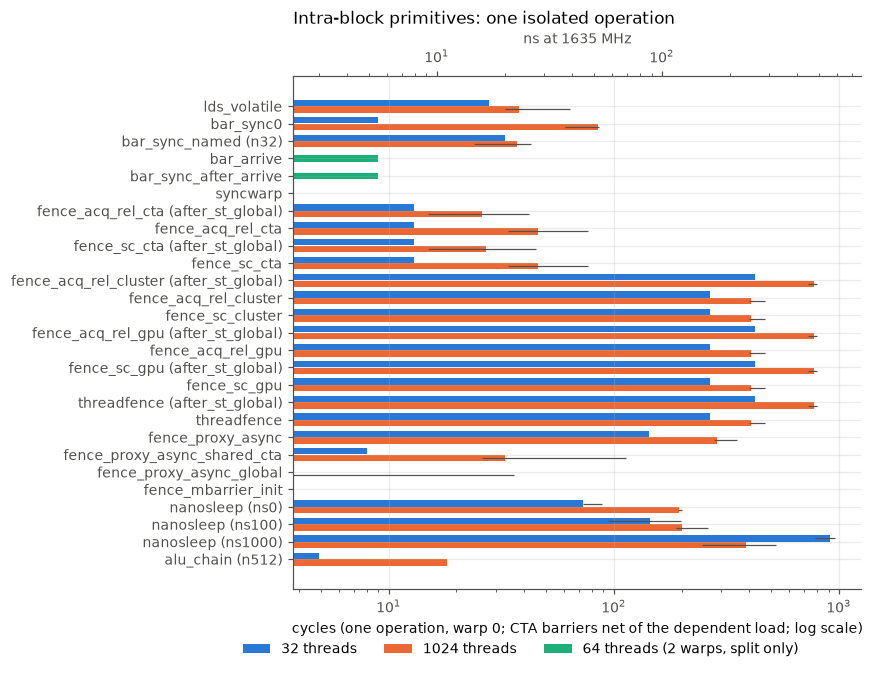

In [4]:
fig, ax = plt.subplots(figsize=(8, 6.2))
s = t[(t["mode"] == "single") & ~t.detail.str.contains("_n(?:128|512)", regex=True)]
s = s[~((s.primitive == "bar_sync_named") & (s.detail != "single_n32"))].sort_values(["primitive", "detail"])
labels = [f"{p}" + ("" if d == "single" else f" ({d.replace('single_', '')})") for p, d in zip(s.primitive, s.detail)]
uniq = list(dict.fromkeys(labels))
y = np.arange(len(uniq))
for i, bt in enumerate([32, 1024, 64]):
    q = s[s.block_threads == bt].set_index(s[s.block_threads == bt].apply(
        lambda r: f"{r.primitive}" + ("" if r.detail == "single" else f" ({r.detail.replace('single_', '')})"), axis=1))
    q = q.reindex(uniq)
    off = 0 if bt == 64 else (i - 0.5) * 0.38
    ax.barh(y + off, q["median"], height=0.36, color=C[i], label=f"{bt} threads" + (" (2 warps, split only)" if bt == 64 else ""),
            xerr=[q["median"] - q.p5, q.p95 - q["median"]], error_kw=dict(ecolor=INK2, lw=0.8))
ax.set_yticks(y, uniq)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("cycles (one operation, warp 0; CTA barriers net of the dependent load; log scale)")
ax.set_title("Intra-block primitives: one isolated operation", loc="left")
ns_axis(ax, "x")
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.08), ncol=3)
fig.tight_layout()
plt.show()

**Reading K1.**

- **CTA barrier.** `bar.sync 0` (`__syncthreads()`) costs **9 cycles for one warp**, 13 for 4 warps, 41 for 16 and 85 for 32 warps (one isolated barrier, all warps arriving together). Back to back the rate is 14 / 20 / 44 / 76 cycles per barrier.
- **Named barrier.** A counted named barrier (`bar.sync 1, N`) is slower than `bar.sync 0` at small counts: 33 cycles with one participating warp, 26.5 back to back. Its cost follows the number of *participating* warps: N = 32 costs the same with 32 or 1024 threads in the CTA.
- **Producer/consumer split.** `bar.arrive` issues in 9 cycles, and a consumer whose producer arrived earlier passes `bar.sync` in 9 cycles.
- **Instructions that compile to nothing.** `__syncwarp()` in convergent code and `fence.mbarrier_init.release.cluster` compile to no instruction at all (a `NOP`) and cost nothing.
- **CTA-scope fences.** `fence.{acq_rel,sc}.cta` (`MEMBAR.ALL.CTA` / `MEMBAR.SC.CTA`) costs 13 cycles for one warp and 46 for 32 warps.
- **GPU- and cluster-scope fences.** Every `.gpu` or `.cluster` fence, `sc` or `acq_rel`, and `__threadfence()` compiles to the same `MEMBAR.*.GPU; ERRBAR; CGAERRBAR; CCTL.IVALL`. All of them cost **268 cycles** for one warp with no store since the previous fence and **424** behind one pending store per thread. At 32 warps the two figures are 407 and 776. There is no cheaper cluster-scope fence.
- **Proxy fences.**
  - `fence.proxy.async` (all spaces: `MEMBAR.ALL.GPU; FENCE.VIEW.ASYNC.S`) costs 144–287 cycles.
  - The shared-memory form (`MEMBAR.ALL.CTA; FENCE.VIEW.ASYNC.S`) costs 8–33.
  - `fence.proxy.async.global` (`FENCE.VIEW.ASYNC.G`) costs nothing in isolation and 4 cycles per fence back to back.
- **`nanosleep`.** Back to back, `nanosleep(100)` and `nanosleep(1000)` settle at 208 and 1669 cycles per call (127 ns and 1.02 µs). An isolated call is not reproducible: `nanosleep(1000)` returned after 918 [786–966] cycles with one warp and 388 [247–526] with 32 warps. `nanosleep(0)` still costs 73–195 cycles.
- **Dependent `mad.lo`.** 4.9 cycles each with up to 4 warps per SM, 9.1 with 16 warps and 18.2 with 32 warps. The SM's integer multiply-add issue rate limits it beyond 4 warps. This chain is the "independent work" of the split-phase test below.

### 4.2 Cluster barrier components (K2)

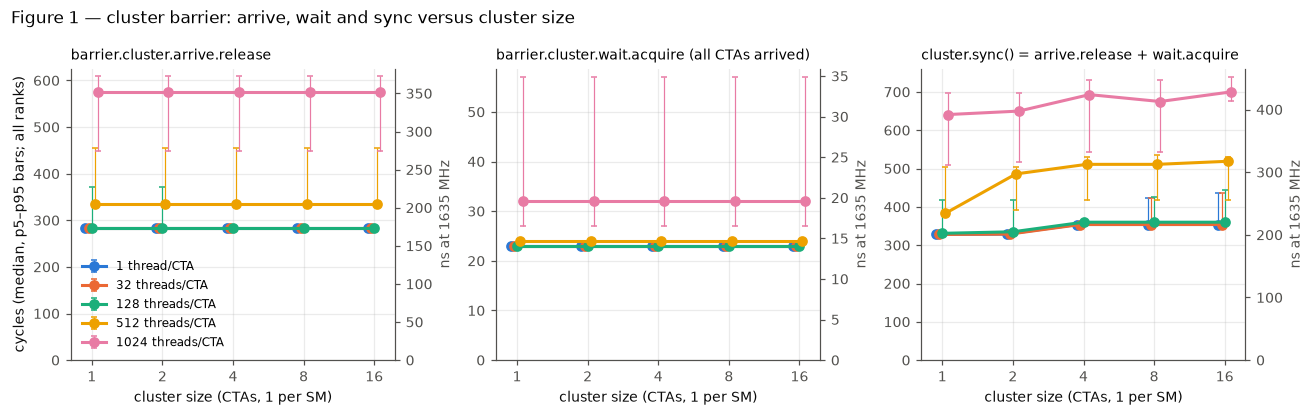

In [5]:
k2 = K["k2"]
BT = [1, 32, 128, 512, 1024]
CS = [1, 2, 4, 8, 16]
panels = [("cluster_arrive_release", "single", "barrier.cluster.arrive.release"),
          ("cluster_wait_acquire", "all_arrived", "barrier.cluster.wait.acquire (all CTAs arrived)"),
          ("cluster_sync", "single", "cluster.sync() = arrive.release + wait.acquire")]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (prim, var, title) in zip(axs, panels):
    s = stats(sel(k2, primitive=prim, variant=var), ["cs", "block_threads"])
    for i, bt in enumerate(BT):
        q = s[s.block_threads == bt].sort_values("cs")
        ax.errorbar(q.cs + (i - 2) * 0.03 * q.cs, q["median"], yerr=[q["median"] - q.p5, q.p95 - q["median"]], marker="o",
                    color=C[i], capsize=2, elinewidth=0.8, label=f"{bt} thread{'s' if bt > 1 else ''}/CTA")
    ax.set_xscale("log", base=2)
    ax.set_xticks(CS, [str(c) for c in CS])
    ax.set_xlabel("cluster size (CTAs, 1 per SM)")
    ax.set_title(title, loc="left", fontsize=9)
    ax.set_ylim(bottom=0)
    ns_axis(ax)
axs[0].set_ylabel("cycles (median, p5–p95 bars; all ranks)")
axs[0].legend(fontsize=8)
fig.suptitle("Figure 1 — cluster barrier: arrive, wait and sync versus cluster size", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [6]:
t = table(sel(k2, primitive=["cluster_arrive_release", "cluster_arrive_relaxed", "cluster_wait_acquire", "cluster_sync"],
              variant=["single", "after_st_global", "all_arrived"]), ["primitive", "variant", "block_threads", "cs"])
pv = t.pivot_table(index=["primitive", "variant", "block_threads"], columns="cs", values="median [p5–p95]", aggfunc="first", observed=True)
pv.columns = [f"CS {c}" for c in pv.columns]
display(Markdown("**Cluster barrier components (cycles, median [p5–p95], all ranks pooled)**"))
display(pv)

**Cluster barrier components (cycles, median [p5–p95], all ranks pooled)**

CS 1            CS 2            CS 4            CS 8           CS 16
primitive              variant         block_threads                                                                               
cluster_arrive_relaxed single          1                 22 [22–22]      22 [22–22]      22 [22–22]      22 [22–22]      22 [22–22]
                                       32                22 [22–22]      22 [22–22]      22 [22–22]      22 [22–22]      22 [22–22]
                                       128               22 [22–22]      22 [22–22]      22 [22–22]      22 [22–22]      22 [22–22]
                                       512               26 [26–27]      26 [26–27]      26 [26–27]      26 [26–27]      26 [26–27]
                                       1024              44 [44–44]      44 [44–44]      44 [44–44]      44 [44–44]      44 [44–44]
cluster_arrive_release after_st_global 1              407 [405–408]   518 [405–552]   525 [404–560]   523 [403–587]   534 [394–575]
                                       32             406 [404–407]   520 [405–553]   525 [404–558]   523 [403–588]   533 [394–575]
                                       128            406 [404–505]   526 [406–552]   480 [403–557]   532 [403–588]   549 [405–587]
                                       512            443 [441–652]   586 [441–744]   605 [459–780]   607 [460–783]   632 [471–820]
                                       1024           729 [609–766]  757 [610–1015]  783 [628–1040]  776 [624–1019]  791 [641–1048]
                       single          1              284 [284–284]   284 [284–284]   284 [284–284]   284 [284–284]   284 [284–284]
                                       32             284 [284–284]   284 [284–284]   284 [284–284]   284 [284–284]   284 [284–284]
                                       128            284 [284–372]   284 [284–372]   284 [284–284]   284 [284–284]   284 [284–284]
                                       512            335 [335–455]   335 [335–455]   335 [335–455]   335 [335–455]   335 [335–455]
                                       1024           575 [448–609]   575 [448–609]   575 [448–609]   575 [448–609]   575 [448–609]
cluster_sync           single          1              328 [328–328]   329 [329–329]   354 [354–354]   354 [354–423]   354 [354–437]
                                       32             328 [328–328]   329 [329–329]   354 [354–354]   354 [354–423]   354 [354–437]
                                       128            331 [331–419]   335 [335–419]   360 [360–360]   360 [360–427]   360 [360–443]
                                       512            383 [383–504]   486 [392–505]   511 [418–530]   511 [418–535]   519 [417–529]
                                       1024           641 [509–696]   650 [518–698]   693 [543–732]   675 [543–730]   700 [676–740]
cluster_wait_acquire   all_arrived     1                 23 [23–23]      23 [23–23]      23 [23–23]      23 [23–23]      23 [23–23]
                                       32                23 [23–23]      23 [23–23]      23 [23–23]      23 [23–23]      23 [23–23]
                                       128               23 [23–23]      23 [23–23]      23 [23–23]      23 [23–23]      23 [23–23]
                                       512               24 [24–24]      24 [24–24]      24 [24–24]      24 [24–24]      24 [24–24]
                                       1024              32 [27–57]      32 [27–57]      32 [27–57]      32 [27–57]      32 [27–57]

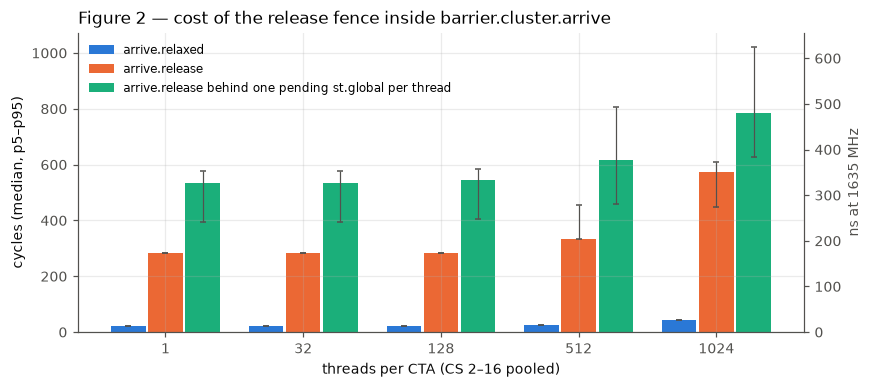

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
q = sel(k2, cs=[2, 4, 8, 16])
bars = [("cluster_arrive_relaxed", "single", "arrive.relaxed"), ("cluster_arrive_release", "single", "arrive.release"),
        ("cluster_arrive_release", "after_st_global", "arrive.release behind one pending st.global per thread")]
x = np.arange(len(BT))
for i, (prim, var, lab) in enumerate(bars):
    s = stats(sel(q, primitive=prim, variant=var), ["block_threads"]).set_index("block_threads").reindex(BT)
    ax.bar(x + (i - 1) * 0.27, s["median"], width=0.25, color=C[i], label=lab,
           yerr=[s["median"] - s.p5, s.p95 - s["median"]], error_kw=dict(ecolor=INK2, lw=0.8, capsize=2))
ax.set_xticks(x, [f"{b}" for b in BT])
ax.set_xlabel("threads per CTA (CS 2–16 pooled)")
ax.set_ylabel("cycles (median, p5–p95)")
ax.set_title("Figure 2 — cost of the release fence inside barrier.cluster.arrive", loc="left")
ns_axis(ax)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

In [8]:
# Delay test: the last rank (CS-1) arrives D cycles late; the others time their wait.
k2d = sel(k2, primitive="cluster_wait_acquire", variant=["delay0", "delay500", "delay2000", "delay2000_relaxed_arrive"])
k2d = k2d[(k2d["rank"] != k2d.cs - 1) & (k2d.cs > 1)]
D = {"delay0": 0, "delay500": 500, "delay2000": 2000, "delay2000_relaxed_arrive": 2000}
k2d = k2d.assign(excess=k2d.per_op - k2d.variant.map(D).astype(float))
t = table(k2d, ["variant", "block_threads", "cs"], "excess")
pv = t.pivot_table(index=["variant", "block_threads"], columns="cs", values="median [p5–p95]", aggfunc="first", observed=True)
pv.columns = [f"CS {c}" for c in pv.columns]
display(Markdown("**Wait of the punctual ranks minus the delay D of the last rank (cycles, median [p5–p95])**"))
display(pv)
# Split phase: arrive.release, 512 dependent mad.lo, wait.acquire — compared with the parts measured separately
alu = stats(sel(K["k1"], primitive="alu_chain"), ["block_threads"]).set_index("block_threads")["median"] * 512
rows = []
for bt in BT:
    for cs in [2, 16]:
        g = lambda p, v: sel(k2, primitive=p, variant=v, block_threads=bt, cs=cs).per_op.median()
        a, w, tot = g("cluster_arrive_release", "single"), g("cluster_wait_acquire", "all_arrived"), g("cluster_split_phase", "alu512")
        s_ = g("cluster_sync", "single")
        al = alu.get(bt, alu.get(32)) if bt > 1 else alu.get(32)
        rows.append([bt, cs, a, al, w, a + al + w, tot, s_ + al, tot - al])
display(Markdown("**Split-phase barrier (cycles, medians): arrive, 512 dependent mad.lo (measured alone in K1 at the same thread "
                 "count; 32 threads for the 1-thread case), wait**"))
display(pd.DataFrame(rows, columns=["threads", "CS", "arrive", "ALU work alone", "wait (all arrived)", "sum of parts",
                                    "measured split phase", "sync + ALU (no overlap)", "split − ALU"]).round(0).set_index(["threads", "CS"]))

**Wait of the punctual ranks minus the delay D of the last rank (cycles, median [p5–p95])**

CS 2           CS 4           CS 8          CS 16
variant                  block_threads                                                            
delay0                   1                 85 [85–85]  110 [110–110]  106 [106–121]  103 [103–103]
                         32                85 [85–85]  110 [110–110]  106 [106–108]  103 [103–103]
                         128               88 [45–88]  113 [113–113]  109 [109–112]  106 [106–129]
                         512            180 [125–201]  207 [133–244]  204 [149–244]  227 [144–244]
                         1024           197 [135–319]  230 [160–350]  239 [159–363]  243 [168–368]
delay2000                1              113 [113–113]  138 [138–138]  134 [134–134]  131 [131–131]
                         32             113 [113–113]  138 [138–138]  134 [134–134]  131 [131–131]
                         128             116 [56–116]  141 [141–141]  137 [137–137]  134 [134–134]
                         512             184 [90–184]  209 [115–209]  205 [111–205]  202 [108–202]
                         1024            162 [91–294]  188 [115–316]  184 [111–312]  182 [109–313]
delay2000_relaxed_arrive 1              113 [113–113]  138 [138–138]  134 [134–134]  131 [131–131]
                         32             113 [113–113]  138 [138–138]  134 [134–134]  131 [131–131]
                         128            113 [113–113]  138 [138–138]  134 [134–134]  131 [131–131]
                         512            139 [135–140]  164 [160–165]  160 [156–161]  157 [153–161]
                         1024           199 [170–225]  224 [195–250]  220 [191–246]  217 [188–243]
delay500                 1                 92 [92–92]  117 [117–117]  113 [113–113]  110 [110–110]
                         32                92 [92–92]  117 [117–117]  113 [113–113]  110 [110–110]
                         128               95 [35–95]  120 [120–120]  116 [116–116]  113 [113–113]
                         512             173 [79–175]  198 [104–200]  193 [100–201]   191 [97–192]
                         1024            165 [93–296]  199 [118–321]  186 [115–317]  185 [111–314]

**Split-phase barrier (cycles, medians): arrive, 512 dependent mad.lo (measured alone in K1 at the same thread count; 32 threads for the 1-thread case), wait**

arrive  ALU work alone  wait (all arrived)  sum of parts  measured split phase  sync + ALU (no overlap)  split − ALU
threads CS                                                                                                                      
1       2    284.0          2509.0                23.0        2816.0                2872.0                   2838.0        363.0
        16   284.0          2509.0                23.0        2816.0                2872.0                   2863.0        363.0
32      2    284.0          2509.0                23.0        2816.0                2810.0                   2838.0        301.0
        16   284.0          2509.0                23.0        2816.0                2810.0                   2863.0        301.0
128     2    284.0          2509.0                23.0        2816.0                2810.0                   2844.0        301.0
        16   284.0          2509.0                23.0        2816.0                2810.0                   2869.0        301.0
512     2    335.0          4650.0                24.0        5009.0                4934.0                   5136.0        284.0
        16   335.0          4650.0                24.0        5009.0                4934.0                   5169.0        284.0
1024    2    575.0          9295.0                32.0        9902.0                9817.0                   9945.0        522.0
        16   575.0          9295.0                32.0        9902.0                9817.0                   9995.0        522.0

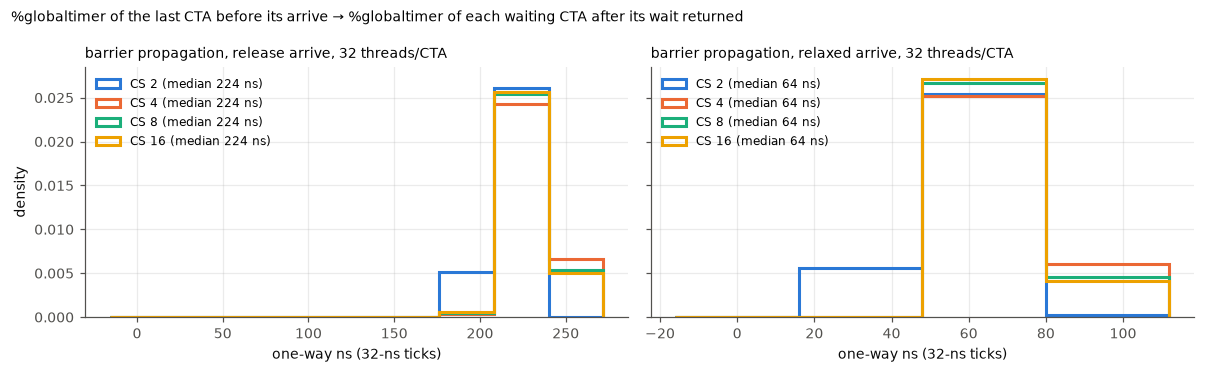

**One-way barrier propagation (ns, median [p5–p95]; %globaltimer ticks are 32 ns)**

CS 2           CS 4           CS 8          CS 16
primitive                      block_threads                                                            
cluster_barrier_relaxed_arrive 1                 64 [32–64]     64 [32–64]     64 [32–64]     64 [32–64]
                               32                64 [32–64]     64 [64–96]     64 [64–96]     64 [64–96]
                               128               64 [32–64]     64 [64–96]     64 [64–96]     64 [64–96]
                               512               96 [64–96]    96 [64–128]    96 [64–128]    96 [64–128]
                               1024            128 [96–160]  160 [128–160]   160 [96–160]   160 [96–160]
cluster_barrier_release_arrive 1              224 [192–224]  224 [192–224]  224 [192–224]  224 [192–224]
                               32             224 [192–224]  224 [224–256]  224 [224–256]  224 [224–256]
                               128            224 [192–224]  224 [224–256]  224 [224–256]  224 [224–256]
                               512            256 [256–288]  288 [256–288]  288 [256–288]  288 [256–288]
                               1024           352 [320–352]  352 [320–384]  352 [320–384]  352 [320–384]

In [9]:
p2 = P["k2"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, prim, title in zip(axs, ["cluster_barrier_release_arrive", "cluster_barrier_relaxed_arrive"],
                           ["release arrive", "relaxed arrive"]):
    q = sel(p2, primitive=prim, block_threads=32)
    bins = np.arange(-16, q.one_way_ns.quantile(0.995) + 48, 32)
    for i, cs in enumerate([2, 4, 8, 16]):
        v = q[q.cs == cs].one_way_ns
        ax.hist(v, bins=bins, histtype="step", lw=2, color=C[i], density=True, label=f"CS {cs} (median {v.median():.0f} ns)")
    ax.set_xlabel("one-way ns (32-ns ticks)")
    ax.set_title(f"barrier propagation, {title}, 32 threads/CTA", loc="left", fontsize=9)
    ax.legend(fontsize=8)
axs[0].set_ylabel("density")
fig.suptitle("%globaltimer of the last CTA before its arrive → %globaltimer of each waiting CTA after its wait returned",
             x=0.01, ha="left", fontsize=9)
fig.tight_layout()
plt.show()
t = table(p2, ["primitive", "block_threads", "cs"], "one_way_ns")
pv = t.pivot_table(index=["primitive", "block_threads"], columns="cs", values="median [p5–p95]", aggfunc="first", observed=True)
pv.columns = [f"CS {c}" for c in pv.columns]
display(Markdown("**One-way barrier propagation (ns, median [p5–p95]; %globaltimer ticks are 32 ns)**"))
display(pv)

In [10]:
# Which SMs the single cluster occupied (rank → smid), from the K2 rows
pl = K["k2"].groupby(["cs", "rank"], observed=True).smid.agg(lambda s: ",".join(str(x) for x in sorted(s.unique()))).unstack("rank")
display(Markdown("**Placement of the single cluster (smid per rank, all K2 launches)**"))
display(pl.fillna(""))

**Placement of the single cluster (smid per rank, all K2 launches)**

rank,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
cs,,,,,,,,,,,,,,,,
1,124,,,,,,,,,,,,,,,
2,124,125,,,,,,,,,,,,,,
4,0,1,16,17,,,,,,,,,,,,
8,0,1,16,17,32,33,48,49,,,,,,,,
16,2,3,18,19,34,35,50,51,64,65,78,79,92,93,106,107


**Reading K2.**

- **Arrive.** `barrier.cluster.arrive.release` costs **284 cycles** for 1–128 threads per CTA, 335 for 512 and 575 for 1024, the same for every cluster size from 1 to 16. The `.relaxed` arrive costs 22 / 26 / 44 cycles. The difference, ≈ 262 cycles, is the release fence (`MEMBAR.ALL.GPU; ERRBAR; CGAERRBAR`), i.e. the same 264-cycle GPU-scope fence as in K1. Behind one pending store per thread the release arrive costs 518–549 cycles (CS ≥ 2, ≤ 128 threads), 586–632 at 512 threads and 757–791 at 1024. For the single-CTA cluster (CS 1) it costs 406–443 cycles at ≤ 512 threads (729 at 1024), cheaper than at CS ≥ 2.
- **Wait.** `barrier.cluster.wait.acquire` after everyone has arrived costs **23 cycles** (32 at 1024 threads).
- **cluster.sync().** 328–335 cycles at CS 1–2 and 354–360 at CS 4–16 (≤ 128 threads). It is therefore almost entirely the release fence plus ≈ 45–70 cycles of rendezvous.
- **Propagation.** When the last CTA arrives late, the others are released ≈ 64 ns (≈ 105 cycles) after its relaxed arrive, and ≈ 224 ns (≈ 366 cycles) after its release arrive (fence included). This holds at every cluster size from 2 to 16, for up to 128 threads per CTA; at 512 and 1024 threads the propagation grows to 96–160 ns (relaxed) and 256–384 ns (release). The wait of the punctual CTAs exceeds the delay D (0–2000 cycles) by 85–113 cycles at CS 2 and 103–138 cycles at CS 4–16, the same for the release and the relaxed arrive. With the release form, the punctual CTAs' own release arrive delays the start of their wait by as much as the late CTA's fence delays the signal. Most of these values are perfectly repeatable: p5 = p95 in most configurations up to 128 threads.
- **Split phase.** For 1–128 threads, arrive (284) + 512 dependent `mad.lo` (2510) + wait (23) = 2817 cycles, and the measured split-phase sequence takes 2810–2872. The release fence is paid by the arriving warp before it can issue the independent work: splitting arrive and wait hides only the time spent waiting for *other* CTAs, never the fence.

### 4.3 mbarrier operations (K3)

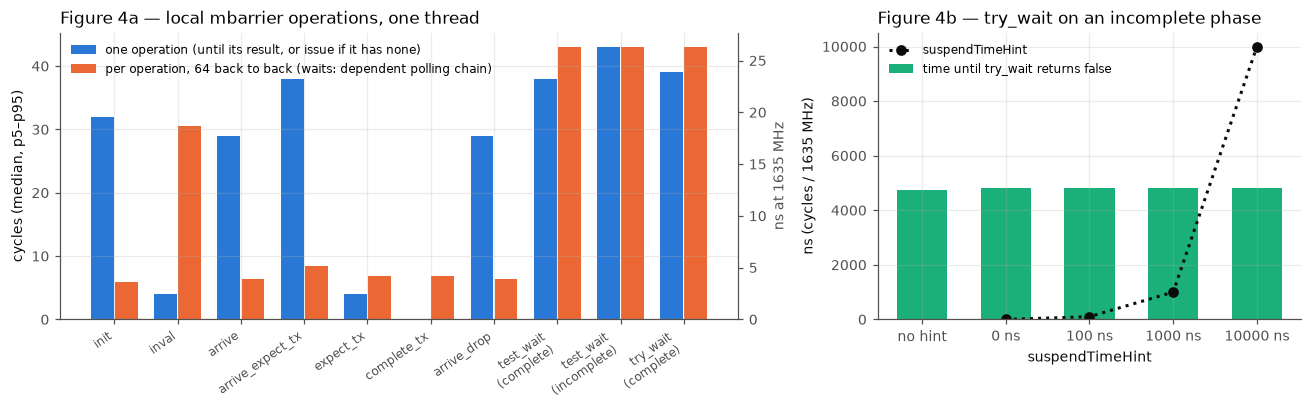

In [11]:
k3 = K["k3"]
loc = sel(k3, cs=0, block_threads=1)
OPS = ["mbar_init", "mbar_inval", "mbar_arrive", "mbar_arrive_expect_tx", "mbar_expect_tx", "mbar_complete_tx", "mbar_arrive_drop"]
WAITS = [("mbar_test_wait", "complete", "chain64_complete"), ("mbar_test_wait", "incomplete", "chain64_incomplete"),
         ("mbar_try_wait", "complete", "chain64_complete")]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axs[0]
labs, single, burst = [], [], []
for op in OPS:
    labs.append(op.replace("mbar_", ""))
    single.append(stats(sel(loc, primitive=op, variant="single"), ["primitive"]).iloc[0])
    burst.append(stats(sel(loc, primitive=op, variant="unroll64"), ["primitive"]).iloc[0])
for op, v1, v64 in WAITS:
    labs.append(op.replace("mbar_", "") + f"\n({v1})")
    single.append(stats(sel(loc, primitive=op, variant=v1), ["primitive"]).iloc[0])
    burst.append(stats(sel(loc, primitive=op, variant=v64), ["primitive"]).iloc[0])
x = np.arange(len(labs))
for i, (vals, lab) in enumerate([(single, "one operation (until its result, or issue if it has none)"),
                                 (burst, "per operation, 64 back to back (waits: dependent polling chain)")]):
    m = np.array([v["median"] for v in vals]); lo = np.array([v.p5 for v in vals]); hi = np.array([v.p95 for v in vals])
    ax.bar(x + (i - 0.5) * 0.38, m, width=0.36, color=C[i], label=lab, yerr=[m - lo, hi - m], error_kw=dict(ecolor=INK2, lw=0.8))
ax.set_xticks(x, labs, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("cycles (median, p5–p95)")
ax.set_title("Figure 4a — local mbarrier operations, one thread", loc="left")
ax.legend(fontsize=8, loc="upper left")
ns_axis(ax)
ax = axs[1]
inc = stats(sel(k3, primitive="mbar_try_wait", variant=["incomplete_nohint", "incomplete_hint0", "incomplete_hint100",
                                                         "incomplete_hint1000", "incomplete_hint10000"]), ["variant"])
hint = {"incomplete_nohint": None, "incomplete_hint0": 0, "incomplete_hint100": 100, "incomplete_hint1000": 1000, "incomplete_hint10000": 10000}
inc["hint"] = inc.variant.map(hint)
inc = inc.sort_values("hint", na_position="first")
xx = np.arange(len(inc))
ax.bar(xx, inc["median"] / MHZ * 1e3, color=C[2], width=0.6, label="time until try_wait returns false")
ax.plot(xx, inc.hint, ls=":", marker="o", color=INK, label="suspendTimeHint")
ax.set_xticks(xx, ["no hint" if pd.isna(h) else f"{int(h)} ns" for h in inc.hint])
ax.set_xlabel("suspendTimeHint")
ax.set_ylabel(f"ns (cycles / {MHZ:.0f} MHz)")
ax.set_title("Figure 4b — try_wait on an incomplete phase", loc="left")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

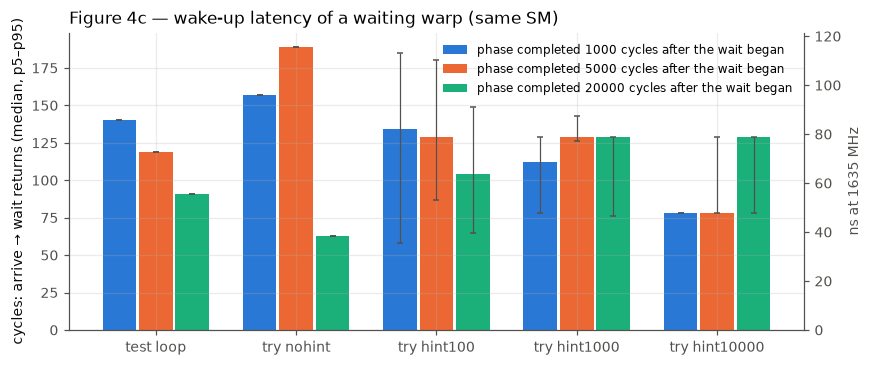

**mbarrier.arrive by many threads on one barrier (cycles per arrive instruction; warp 0 / slowest warp)**

warp 0 slowest warp
variant  block_threads                         
single   1              29 [29–29]   29 [29–29]
         32             29 [29–29]   29 [29–29]
         128            32 [32–32]   32 [32–32]
         512            43 [43–45]   43 [43–45]
         1024           59 [54–68]   65 [61–75]
unroll64 1                 6 [6–6]      6 [6–6]
         32                6 [6–6]      6 [6–6]
         128               8 [8–8]      8 [8–8]
         512            33 [33–33]   33 [33–33]
         1024           65 [65–65]   65 [65–65]

In [12]:
w = sel(k3, primitive="mbar_wakeup")
w = w.assign(form=w.variant.str.rsplit("_x", n=1).str[0], X=w.variant.str.rsplit("_x", n=1).str[1].astype(int))
FORMS = ["test_loop", "try_nohint", "try_hint100", "try_hint1000", "try_hint10000"]
fig, ax = plt.subplots(figsize=(8, 3.4))
Xs = sorted(w.X.unique())
for i, X in enumerate(Xs):
    s = stats(w[w.X == X], ["form"], "per_op").set_index("form").reindex(FORMS)
    ax.bar(np.arange(len(FORMS)) + (i - (len(Xs) - 1) / 2) * 0.26, s["median"], width=0.24, color=C[i],
           yerr=[s["median"] - s.p5, s.p95 - s["median"]], error_kw=dict(ecolor=INK2, lw=0.8, capsize=2),
           label=f"phase completed {X} cycles after the wait began")
ax.set_xticks(np.arange(len(FORMS)), [f.replace("_", " ") for f in FORMS])
ax.set_ylabel("cycles: arrive → wait returns (median, p5–p95)")
ax.set_title("Figure 4c — wake-up latency of a waiting warp (same SM)", loc="left")
ax.legend(fontsize=8)
ns_axis(ax)
fig.tight_layout()
plt.show()
t = table(sel(k3, primitive="mbar_arrive", variant=["single", "unroll64"]), ["variant", "block_threads"])
t2 = table(sel(k3, primitive="mbar_arrive", variant=["single", "unroll64"]), ["variant", "block_threads"], "per_op_max")
t["slowest warp"] = t2["median [p5–p95]"]
display(Markdown("**mbarrier.arrive by many threads on one barrier (cycles per arrive instruction; warp 0 / slowest warp)**"))
display(t.set_index(["variant", "block_threads"])[["median [p5–p95]", "slowest warp"]].rename(columns={"median [p5–p95]": "warp 0"}))

In [13]:
rem = table(sel(k3, cs=2), ["primitive", "variant"])
display(Markdown("**Remote (CS 2) mbarrier arrive, rank 0 → rank 1 (cycles, median [p5–p95]); mbar_remote_wait = rank 1's wait "
                 "after rank 0 spun 2000 cycles**"))
display(rem.set_index(["primitive", "variant"])[["median [p5–p95]", "n"]])
p3 = P["k3"]
display(Markdown("**One-way propagation of a remote arrive (ns): %globaltimer before the arrive on rank 0 → try_wait returns true on rank 1**"))
display(table(p3, ["primitive", "smid_src", "smid_dst"], "one_way_ns").set_index(["primitive", "smid_src", "smid_dst"])[["median [p5–p95]", "mean", "n"]])

**Remote (CS 2) mbarrier arrive, rank 0 → rank 1 (cycles, median [p5–p95]); mbar_remote_wait = rank 1's wait after rank 0 spun 2000 cycles**

median [p5–p95]     n
primitive                         variant                                 
mbar_arrive_release_cluster_local single               298 [298–298]  5120
                                  unroll64             270 [270–270]  5120
mbar_remote_arrive_relaxed        single                     0 [0–0]  5120
                                  unroll64                   5 [5–5]  5120
mbar_remote_arrive_release        single               269 [269–269]  5120
                                  unroll64             313 [313–313]  5120
mbar_remote_wait                  relaxed_spin2000  2201 [2201–2201]  5120
                                  release_spin2000  2470 [2470–2470]  5120

**One-way propagation of a remote arrive (ns): %globaltimer before the arrive on rank 0 → try_wait returns true on rank 1**

,,,median [p5–p95],mean,n
primitive,smid_src,smid_dst,,,
mbar_remote_arrive_relaxed,124,125,96 [64–96],83.68750,5120
mbar_remote_arrive_release,124,125,256 [224–256],249.88125,5120


**Reading K3 (one thread unless stated).**

- **Local operations.** These are the times until the result is back, or the issue cost for operations without a result.
  - `mbarrier.init` 32 cycles (6 per init back to back; it carries a `FENCE.VIEW.ASYNC.S`).
  - `inval` 4 cycles in isolation, 31 per inval back to back.
  - `arrive` 29, `arrive_drop` 29, `arrive.expect_tx` 38, back to back 6–8.5.
  - `expect_tx` and `complete_tx` issue in 0–4 cycles (6.8 back to back).
- **Phase check.** On a completed phase it takes 38 (`test_wait`) or 39 cycles (`try_wait`); one iteration of a dependent polling loop is 43 cycles.
- **`try_wait` on an incomplete phase.** It returns false after **7765 cycles (4.75 µs)** without a hint. With a suspend-time hint of 0, 100, 1000 or 10 000 ns it returns after 7850–7869 cycles (4.8 µs), whatever the hint. The hint is compiled into `TRYWAIT; @!P NANOSLEEP.SYNCS hint; @!P PHASECHK`. With a hint the warp spends 91 % of its samples in `NANOSLEEP.SYNCS`, without one it spends them in the `TRYWAIT` itself.
- **Wake-up.** When the phase completes during the wait, the waiting warp resumes 63–189 cycles later (`try_wait` loop without hint), 78–134 cycles (with hints) or 91–140 cycles (`test_wait` loop). The value depends on how long the wait had already lasted (X), i.e. on where in its polling or suspension cycle the completion fell.
- **Many arriving threads.** When every thread of a CTA arrives on one barrier, one arrive instruction (coalesced per warp) takes 29 cycles for one warp, 32 for 4 warps, 43 for 16 and 59–65 for 32 warps. Back to back, 16 or 32 warps together sustain one warp-level arrive every ≈ 2 cycles per SM.
- **Remote arrive (CS 2).** A remote `mbarrier.arrive.release.cluster` costs 269 cycles to issue (its release fence), the `.relaxed.cluster` form 0 (5 per arrive back to back). The local `.release.cluster` arrive costs 298. The arrive reaches the peer's `try_wait` in 84 ns (mean; median 96 ns) when relaxed and in 250 ns when released.

### 4.4 Signalling between two CTAs of a cluster (K4)

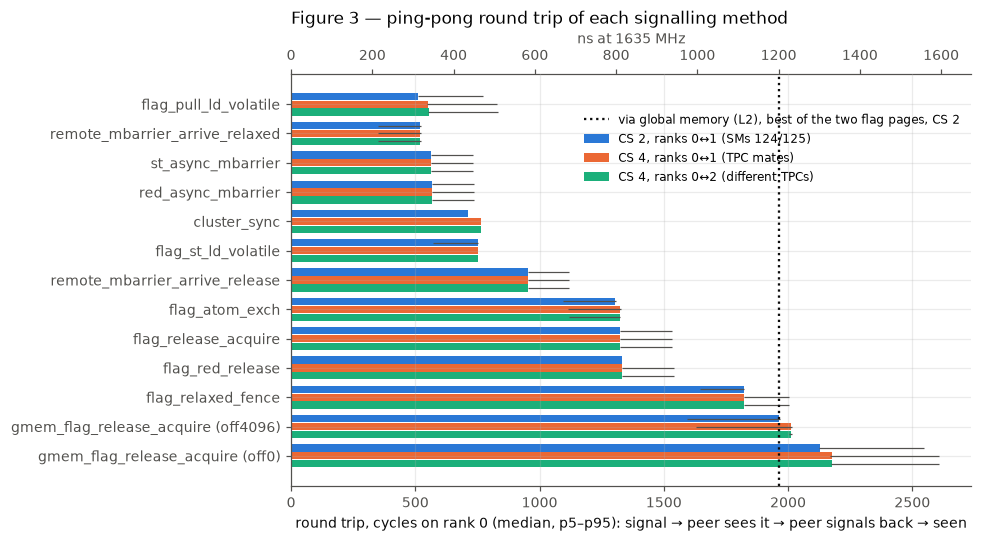

**Round trip (cycles) and one-way delay (ns, 32-ns ticks), median [p5–p95]**

median [p5–p95]                                                                                 one-way ns                              \
place                               CS 2, ranks 0↔1 (SMs 124/125) CS 4, ranks 0↔1 (TPC mates) CS 4, ranks 0↔2 (different TPCs) CS 2, ranks 0↔1 (SMs 124/125) CS 4, ranks 0↔1 (TPC mates)   
method                                                                                                                                                                                     
flag_pull_ld_volatile                               512 [509–772]               552 [546–828]                    553 [552–832]                  160 [96–224]                160 [96–256]   
remote_mbarrier_arrive_relaxed                      517 [350–521]               517 [350–521]                    517 [350–521]                  128 [96–192]                128 [96–192]   
st_async_mbarrier                                   565 [565–733]               565 [565–733]                    565 [565–733]                  160 [96–192]               160 [128–224]   
red_async_mbarrier                                  567 [567–736]               567 [567–736]                    567 [567–736]                  160 [96–224]               160 [128–224]   
cluster_sync                                        712 [712–712]               766 [766–766]                    766 [766–766]                 224 [224–256]               256 [224–256]   
flag_st_ld_volatile                                 754 [573–754]               754 [754–754]                    754 [754–754]                 224 [160–256]               224 [160–288]   
remote_mbarrier_arrive_release                     953 [953–1120]              953 [953–1120]                   953 [953–1120]                 288 [256–352]               320 [256–352]   
flag_atom_exch                                   1302 [1096–1307]            1322 [1116–1327]                 1325 [1119–1325]                 384 [320–448]               384 [352–448]   
flag_release_acquire                             1325 [1325–1531]            1325 [1325–1531]                 1325 [1325–1531]                 384 [352–448]               416 [352–480]   
flag_red_release                                 1333 [1333–1333]            1333 [1333–1539]                 1333 [1333–1539]                 384 [352–448]               416 [352–480]   
flag_relaxed_fence                               1824 [1645–1824]            1824 [1824–2003]                 1824 [1824–2003]                 544 [480–608]               544 [512–608]   
gmem_flag_release_acquire (off4096)              1964 [1594–1969]            2010 [1630–2016]                 2010 [2003–2014]                 576 [480–704]               608 [480–704]   
gmem_flag_release_acquire (off0)                 2130 [2126–2549]            2178 [2170–2607]                 2175 [2171–2606]                 672 [576–800]               672 [576–800]   

                                                                      
place                               CS 4, ranks 0↔2 (different TPCs)  
method                                                                
flag_pull_ld_volatile                                   160 [96–256]  
remote_mbarrier_arrive_relaxed                          128 [96–192]  
st_async_mbarrier                                      160 [128–224]  
red_async_mbarrier                                     160 [128–224]  
cluster_sync                                           256 [224–256]  
flag_st_ld_volatile                                    224 [160–288]  
remote_mbarrier_arrive_release                         288 [256–352]  
flag_atom_exch                                         384 [352–448]  
flag_release_acquire                                   416 [352–448]  
flag_red_release                                       416 [352–480]  
flag_relaxed_fence                                     544 [512–608]  
gmem_flag_release_acquire (off4096)            

In [14]:
p4 = P["k4"].copy()
p4["pair"] = p4.variant.str[-3:]
p4["place"] = np.where(p4.cs == 2, "CS 2, ranks 0↔1 (SMs " + p4.smid_src.astype(str) + "/" + p4.smid_dst.astype(str) + ")",
                       np.where(p4.pair == "r01", "CS 4, ranks 0↔1 (TPC mates)", "CS 4, ranks 0↔2 (different TPCs)"))
p4["method"] = p4.primitive.astype(str) + np.where(p4.primitive == "gmem_flag_release_acquire",
                                                  " (" + p4.variant.str.split("_").str[0] + ")", "")
s = stats(p4, ["method", "place"], "round_trip_cycles")
ref = s[(s.method.str.startswith("gmem")) & s.place.str.startswith("CS 2")]["median"].min()
order = s[s.place.str.startswith("CS 2")].sort_values("median").method.tolist()
places = sorted(s.place.unique(), key=lambda p: (not p.startswith("CS 2"), p))
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(order))
for i, pl in enumerate(places):
    q = s[s.place == pl].set_index("method").reindex(order)
    ax.barh(y + (i - 1) * 0.27, q["median"], height=0.25, color=C[i], label=pl,
            xerr=[q["median"] - q.p5, q.p95 - q["median"]], error_kw=dict(ecolor=INK2, lw=0.8))
ax.axvline(ref, ls=":", color=INK, lw=1.5, label="via global memory (L2), best of the two flag pages, CS 2")
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.set_xlabel("round trip, cycles on rank 0 (median, p5–p95): signal → peer sees it → peer signals back → seen")
ax.set_title("Figure 3 — ping-pong round trip of each signalling method", loc="left")
ns_axis(ax, "x")
ax.legend(fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.93))
fig.tight_layout()
plt.show()
t = table(p4, ["method", "place"], "round_trip_cycles")
t1 = table(p4, ["method", "place"], "one_way_ns")
t["one-way ns"] = t1["median [p5–p95]"]
pv = t.pivot_table(index="method", columns="place", values=["median [p5–p95]", "one-way ns"], aggfunc="first")
pv = pv.reindex(order)
display(Markdown("**Round trip (cycles) and one-way delay (ns, 32-ns ticks), median [p5–p95]**"))
display(pv)

**Reading K4.** Round trip on rank 0, half of it ≈ one hand-off; CS 2, SMs 124/125.

| method | round trip | one-way | what the receiver may assume |
|---|---|---|---|
| peer arrives relaxed on my mbarrier, I `try_wait.acquire.cluster` | **517 cycles** | 128 ns | only the arrival, no data |
| `st.async` / `red.async` (data + byte count on my mbarrier) | **565 / 567 cycles** | 160 ns | the delivered data are visible |
| two `cluster.sync()` | 712 cycles | 224 ns | all CTAs' earlier writes |
| plain remote store + volatile polling | 754 cycles | 224 ns | only the flag word |
| pulling the peer's flag with remote volatile loads | 512 cycles | 160 ns | only the flag word |
| release arrive on the remote mbarrier | 953 cycles | 288 ns | all earlier writes |
| release/acquire flag, release `red`, `atom.exch` | 1302–1333 cycles | 384–416 ns | all earlier writes |
| relaxed flag with a fence on each side | 1824 cycles | 544 ns | all earlier writes |
| global flag (`st.release.gpu` / `ld.acquire.gpu`) | 1964 / 2130 cycles | 576 / 672 ns | all earlier writes |

The two global-flag values belong to the two 4-KiB flag pages, which are homed in different L2 partitions.

- **Cost of release semantics.** Every method that publishes the sender's earlier writes pays a GPU-scope fence per hand-off. In this loop each signal follows the previous iteration's own store, so the fence runs in its "store pending" regime. That is what puts release-based flags at 1300 cycles and hardware-signalled transfers at 565.
- **Placement.** Between TPC mates of a regular GPC (CS 4, ranks 0↔1) and different TPCs of one GPC (ranks 0↔2), every method's round trip is within ≈ 55 cycles of the CS-2 pair. The 0↔1 and 0↔2 pairs agree within a few cycles.

### 4.5 Grid-wide barrier (K5)

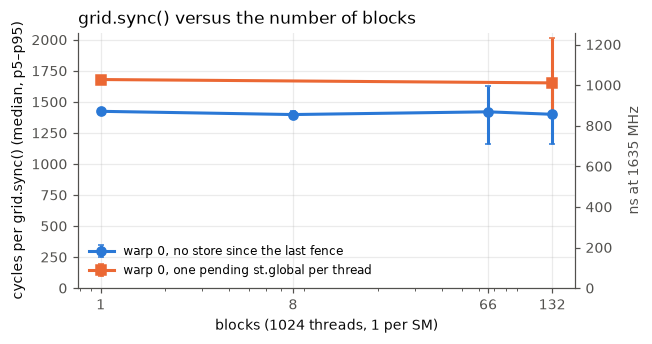

warp 0      slowest warp       n
state                            B                                              
no store since the last fence    1    1424 [1416–1430]  1424 [1416–1430]    5120
                                 8    1398 [1378–1426]  1398 [1378–1426]   40960
                                 66   1420 [1158–1627]  1420 [1158–1627]  337920
                                 132  1400 [1157–1626]  1400 [1157–1626]  675840
one pending st.global per thread 1    1680 [1670–1685]  1680 [1670–1685]    5120
                                 132  1653 [1421–2013]  1653 [1421–2013]  675840

In [15]:
k5 = K["k5"]
k5 = k5.assign(B=k5.variant.str.extract(r"b(\d+)")[0].astype(int),
               state=np.where(k5.variant.str.contains("after_st"), "one pending st.global per thread", "no store since the last fence"))
fig, ax = plt.subplots(figsize=(6, 3.2))
for i, (st_, g) in enumerate(k5.groupby("state")):
    s = stats(g, ["B"])
    ax.errorbar(s.B, s["median"], yerr=[s["median"] - s.p5, s.p95 - s["median"]], marker="os"[i], color=C[i], capsize=2,
                label=f"warp 0, {st_}")
ax.set_xscale("log")
ax.set_xticks([1, 8, 66, 132], ["1", "8", "66", "132"])
ax.set_xlabel("blocks (1024 threads, 1 per SM)")
ax.set_ylabel("cycles per grid.sync() (median, p5–p95)")
ax.set_ylim(bottom=0)
ax.set_title("grid.sync() versus the number of blocks", loc="left")
ns_axis(ax)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
t = table(k5, ["state", "B"]); t["slowest warp"] = table(k5, ["state", "B"], "per_op_max")["median [p5–p95]"]
display(t.set_index(["state", "B"])[["median [p5–p95]", "slowest warp", "n"]].rename(columns={"median [p5–p95]": "warp 0"}))

**Reading K5.**

- **Cost.** `grid.sync()` costs **1398–1424 cycles (≈ 0.86 µs)** with 1, 8, 66 or 132 blocks of 1024 threads, essentially independent of the number of blocks. Behind one pending store per thread it costs 1653–1680 cycles, the same +256-cycle fence step as everywhere else.
- **What it compiles to.** CUDA's grid barrier is a CTA barrier, then one thread per block executes a GPU-scope fence, a global atomic add and a polling loop on that counter (an L2 round trip each), then a second CTA barrier.
- **Sensitivity.** In variants of this loop that differed only in the instructions before the barrier, the cost ranged from 1400 to 2030 cycles.

### 4.6 Where the waiting time goes: stall sampling and instruction counts

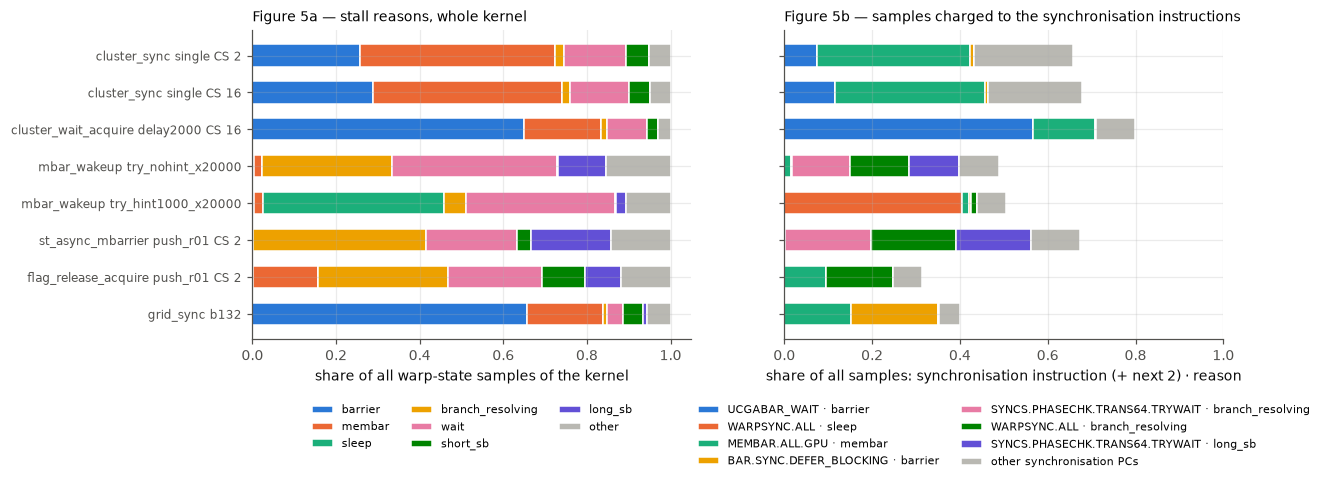

In [16]:
st = pd.read_csv(f"{RES}/07__sync__stalls.csv")
st = st[st.run_id.isin(st.groupby("kernel").run_id.max())]  # the latest ncu invocation of each binary
# A sampled warp is reported at the instruction it waits to issue, often the one after the stalling instruction (ERRBAR
# after MEMBAR, the instruction after NANOSLEEP or BAR.SYNC). Each PC is therefore charged to the nearest preceding
# synchronisation instruction at most 0x20 bytes (two instructions) before it, if any ("owner").
pcs = pd.read_csv(f"{RES}/07__sync__ncu_pcs.csv")
pcs = pcs[pcs.run_id.isin(st.run_id.unique())].copy()
pcs["off"] = pcs.pc_offset.apply(lambda h: int(h, 16))
pcs["op"] = pcs.sass.str.replace(r"^@!?U?P\w+\s+", "", regex=True).str.split().str[0].str.rstrip(";")
SYNCOP = ("UCGABAR_ARV", "UCGABAR_WAIT", "MEMBAR", "SYNCS.PHASECHK", "NANOSLEEP", "BAR.SYNC", "BAR.ARV", "WARPSYNC")
# WARPSYNC: where the idle lanes of a warp whose lane 0 polls are parked (reconvergence point); a warp whose lane 0 sleeps
# in NANOSLEEP.SYNCS is sampled there.
own = []
for (r, l), g in pcs.sort_values("off").groupby(["run_id", "launch_idx"]):
    last = None
    for off, op, pc in zip(g.off, g.op, g.pc_offset):
        if op.startswith(SYNCOP):
            last = (off, op)
        if last is not None and off - last[0] <= 0x20:
            own.append((r, l, pc, last[1]))
OWNER = pd.DataFrame(own, columns=["run_id", "launch_idx", "pc_offset", "owner"])
picks = [("k2", "cluster_sync", "single", 2), ("k2", "cluster_sync", "single", 16), ("k2", "cluster_wait_acquire", "delay2000", 16),
         ("k3", "mbar_wakeup", "try_nohint_x20000", 0), ("k3", "mbar_wakeup", "try_hint1000_x20000", 0),
         ("k4", "st_async_mbarrier", "push_r01", 2), ("k4", "flag_release_acquire", "push_r01", 2), ("k5", "grid_sync", "b132", 0)]
REASONS = ["barrier", "membar", "sleep", "branch_resolving", "wait", "no_inst", "short_sb", "long_sb", "misc", "selected", "not_selected"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1, 1]))
lab, frac_all, frac_pc = [], [], []
for kg, prim, var, cs in picks:
    q = st[(st.kernel == kg) & (st.primitive == prim) & (st.variant == var) & ((st.cs == cs) | (cs == 0))]
    tot = q.samples.sum()
    lab.append(f"{prim} {var}" + (f" CS {cs}" if cs else ""))
    frac_all.append(q.groupby("stall_reason").samples.sum() / tot)
    w = q.merge(OWNER, on=["run_id", "launch_idx", "pc_offset"], how="inner")
    frac_pc.append(w.groupby(["owner", "stall_reason"]).samples.sum() / tot)
F = pd.DataFrame(frac_all, index=lab).fillna(0)
cols = [r for r in REASONS if r in F.columns] + [c for c in F.columns if c not in REASONS]
F = F[cols]
main = [c for c in F.max().sort_values(ascending=False).index[:7]]  # 7 categorical slots + grey "other"
main = [c for c in cols if c in main]
F = pd.concat([F[main], F.drop(columns=main).sum(axis=1).rename("other")], axis=1)
left = np.zeros(len(F))
for i, c in enumerate(F.columns):
    axs[0].barh(np.arange(len(F)), F[c], left=left, color=C[i] if c != "other" else "#b9b8b2", label=c, height=0.6,
                edgecolor="white", linewidth=1)
    left += F[c].values
axs[0].set_yticks(np.arange(len(F)), F.index, fontsize=8)
axs[0].invert_yaxis()
axs[0].set_xlabel("share of all warp-state samples of the kernel")
axs[0].legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
axs[0].set_title("Figure 5a — stall reasons, whole kernel", loc="left", fontsize=9)
G = pd.DataFrame(frac_pc, index=lab).fillna(0)
G.columns = [f"{a} · {b}" for a, b in G.columns]
keep = list(G.max().sort_values(ascending=False).index[:7])
G = pd.concat([G[keep], G.drop(columns=keep).sum(axis=1).rename("other synchronisation PCs")], axis=1)
left = np.zeros(len(G))
for i, c in enumerate(G.columns):
    axs[1].barh(np.arange(len(G)), G[c], left=left, color=C[i] if i < 7 else "#b9b8b2", label=c, height=0.6,
                edgecolor="white", linewidth=1)
    left += G[c].values
axs[1].set_yticks(np.arange(len(G)), [""] * len(G))
axs[1].invert_yaxis()
axs[1].set_xlim(0, 1)
axs[1].set_xlabel("share of all samples: synchronisation instruction (+ next 2) · reason")
axs[1].legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
axs[1].set_title("Figure 5b — samples charged to the synchronisation instructions", loc="left", fontsize=9)
fig.tight_layout()
plt.show()

In [17]:
# Dominant (instruction, stall reason) of every profiled primitive
g = st.groupby(["kernel", "primitive", "variant", "cs", "block_threads", "pc_opcode", "stall_reason"]).samples.sum().reset_index()
tot = g.groupby(["kernel", "primitive", "variant", "cs", "block_threads"]).samples.transform("sum")
g["share"] = g.samples / tot
top = g.sort_values("share", ascending=False).groupby(["kernel", "primitive", "variant", "cs", "block_threads"]).head(1)
top = top[top.kernel.isin(["k2", "k3", "k5"]) | ((top.kernel == "k4") & (top.cs == 2))]  # K1 loops: loop overhead dominates
top = top.sort_values(["kernel", "primitive", "variant", "cs"])
top["share"] = (100 * top.share).round(0).astype(int).astype(str) + " %"
display(Markdown("**Most-sampled (instruction, stall reason) per profiled configuration (share of the kernel's samples; "
                 "K2, K3, K5, and K4 at CS 2 — at CS 4 the two idle CTAs wait in UCGABAR_WAIT)**"))
with pd.option_context("display.max_rows", 300):
    display(top.set_index(["kernel", "primitive", "variant", "cs", "block_threads"])[["pc_opcode", "stall_reason", "share"]])

**Most-sampled (instruction, stall reason) per profiled configuration (share of the kernel's samples; K2, K3, K5, and K4 at CS 2 — at CS 4 the two idle CTAs wait in UCGABAR_WAIT)**

pc_opcode      stall_reason share
kernel primitive                         variant                  cs block_threads                                                        
k2     cluster_arrive_relaxed            single                   2  128                                    ERRBAR            membar  31 %
                                                                  16 128                                    ERRBAR            membar  30 %
       cluster_arrive_release            after_st_global          2  128                                    ERRBAR            membar  41 %
                                                                  16 128                                    ERRBAR            membar  41 %
                                         single                   2  128                                    ERRBAR            membar  35 %
                                                                  16 128                                    ERRBAR            membar  34 %
       cluster_split_phase               alu512                   2  128                                      IMAD              wait  26 %
                                                                  16 128                                      IMAD              wait  26 %
       cluster_sync                      single                   2  128                                    ERRBAR            membar  35 %
                                                                  16 128                                    ERRBAR            membar  34 %
       cluster_wait_acquire              all_arrived              2  128                                       BRA              wait  27 %
                                                                  16 128                                       BRA              wait  26 %
                                         delay0                   2  128                                    ERRBAR            membar  31 %
                                                                  16 128                                    ERRBAR            membar  31 %
                                         delay2000                2  128                              UCGABAR_WAIT           barrier  31 %
                                                                  16 128                              UCGABAR_WAIT           barrier  57 %
                                         delay2000_relaxed_arrive 2  128                              UCGABAR_WAIT           barrier  34 %
                                                                  16 128                              UCGABAR_WAIT           barrier  61 %
                                         delay500                 2  128                                    ERRBAR            membar  24 %
                                                                  16 128                              UCGABAR_WAIT           barrier  31 %
k3     mbar_arrive                       single                   0  512                                       LDS           barrier  31 %
                                                                     1024                                      LDS           barrier  29 %
                                                                     128                                       LDS           barrier  26 %
                                                                     1                                      ERRBAR            membar  25 %
                                                                     32                                     ERRBAR            membar  20 %
                                         unroll64                 0  1024                SYNCS.ARRIVE.TRANS64.A1T0               mio  54 %
                                                                     512                 SYNCS.ARRIVE.TRANS64.A1T0               mio  41 %
                                                                     128  

In [18]:
oc = pd.read_csv(f"{RES}/07__sync__ncu_opcodes.csv")
oc = oc[oc.run_id.isin(oc.groupby("kernel").run_id.max())]
SYNC = ["BAR", "UCGABAR_ARV", "UCGABAR_WAIT", "MEMBAR", "ERRBAR", "CGAERRBAR", "CCTL", "SYNCS", "FENCE", "NANOSLEEP", "STAS", "REDAS", "ATOM", "YIELD"]
o = oc[oc.opcode.isin(SYNC) & (((oc.kernel == "k2") & (oc.cs == 16)) | ((oc.kernel == "k4") & (oc.cs == 2)))]
pv = o.pivot_table(index=["kernel", "primitive", "variant", "cs", "block_threads"], columns="opcode", values="inst_executed",
                   aggfunc="sum", fill_value=0)
pv = (pv / 1024).round(1)[[c for c in SYNC if c in pv.columns]]
display(Markdown("**Synchronisation-related SASS instructions executed per rep (warp-level, all warps and CTAs; "
                 "sass__inst_executed_per_opcode / 1024 reps), K2 at CS 16 (128 threads/CTA: 64 warps) and K4 at CS 2**"))
with pd.option_context("display.max_rows", 300, "display.max_columns", 30):
    display(pv)

**Synchronisation-related SASS instructions executed per rep (warp-level, all warps and CTAs; sass__inst_executed_per_opcode / 1024 reps), K2 at CS 16 (128 threads/CTA: 64 warps) and K4 at CS 2**

opcode                                                                             BAR  UCGABAR_ARV  UCGABAR_WAIT  MEMBAR  ERRBAR  CGAERRBAR   CCTL  SYNCS  FENCE  STAS  REDAS  ATOM  YIELD
kernel primitive                      variant                  cs block_threads                                                                                                            
k2     cluster_arrive_relaxed         single                   16 128            128.0        128.1         128.1    64.1    64.1       64.1  128.1    0.0    0.0   0.0    0.0   0.0    0.0
       cluster_arrive_release         after_st_global          16 128            128.0        128.1         128.1   128.1   128.1      128.1  128.1    0.0    0.0   0.0    0.0   0.0    0.0
                                      single                   16 128            128.0        128.1         128.1   128.1   128.1      128.1  128.1    0.0    0.0   0.0    0.0   0.0    0.0
       cluster_split_phase            alu512                   16 128            128.0        128.1         128.1   128.1   128.1      128.1  128.1    0.0    0.0   0.0    0.0   0.0    0.0
       cluster_sync                   single                   16 128            128.0        128.1         128.1   128.1   128.1      128.1  128.1    0.0    0.0   0.0    0.0   0.0    0.0
       cluster_wait_acquire           all_arrived              16 128            128.0        128.1         128.1   128.1   128.1      128.1  128.1    0.0    0.0   0.0    0.0   0.0    0.0
                                      delay0                   16 128            128.0        128.1         128.1   128.1   128.1      128.1  128.1    0.0    0.0   0.0    0.0   0.0    0.0
                                      delay2000                16 128            128.0        128.1         128.1   128.1   128.1      128.1  128.1    0.0    0.0   0.0    0.0   0.0    0.0
                                      delay2000_relaxed_arrive 16 128            128.0        128.1         128.1    64.1    64.1       64.1  128.1    0.0    0.0   0.0    0.0   0.0    0.0
                                      delay500                 16 128            128.0        128.1         128.1   128.1   128.1      128.1  128.1    0.0    0.0   0.0    0.0   0.0    0.0
k4     cluster_sync                   push_r01                 2  32               0.0          4.0           4.0     8.0     4.0        4.0    4.0    0.0    0.0   0.0    0.0   0.0    0.0
       flag_atom_exch                 push_r01                 2  1                0.0          0.0           0.0     4.0     2.0        2.0    6.9    0.0    0.0   0.0    0.0   2.0    6.9
       flag_pull_ld_volatile          pull_r01                 2  1                0.0          0.0           0.0     0.0     0.0        0.0    0.0    0.0    0.0   0.0    0.0   0.0    4.3
       flag_red_release               push_r01                 2  1                0.0          0.0           0.0     4.0     2.0        2.0    5.1    0.0    0.0   0.0    0.0   2.0    7.1
       flag_relaxed_fence             push_r01                 2  1                0.0          0.0           0.0     8.0     4.0        4.0    4.0    0.0    0.0   0.0    0.0   0.0    5.4
       flag_release_acquire           push_r01                 2  1                0.0          0.0           0.0     4.0     2.0        2.0    5.2    0.0    0.0   0.0    0.0   0.0    5.2
       flag_st_ld_volatile            push_r01                 2  1                0.0          0.0           0.0     0.0     0.0        0.0    0.0    0.0    0.0   0.0    0.0   0.0    4.9
       gmem_flag_release_acquire      off0_r01                 2  1                0.0          0.0           0.0     4.0     2.0        2.0    5.8    0.0    0.0   0.0    0.0   0.0    5.8
                                      off4096_r01              2  1                0.0          0.0           0.0     4.0     2.0        2.0    5.8    0.0    0.0   0.0    0.0   0.0    5.8
       red_async_mbarrier             push_r01      

In [19]:
# SASS of the timed region of k2_arrive_release (aligned form), from the committed dump
sass = open("results/sass/sync_cluster.sass").read()
f = sass[sass.index("Function : _Z17k2_arrive_releaseILb1EEvjjjP3RecPm"):]
lines = [l.strip() for l in f.splitlines()[:200] if l.strip().startswith("/*")]
i = [k for k, l in enumerate(lines) if "CS2R" in l and "SR_CLOCKLO" in l][0]
print("\n".join(lines[i: i + 11]))

/*0340*/                   CS2R R6, SR_CLOCKLO ;
/*0350*/                   IMAD.MOV.U32 R9, RZ, RZ, R6 ;
/*0360*/              @!P1 BRA 0x3c0 ;
/*0370*/                   MEMBAR.ALL.GPU ;
/*0380*/                   ERRBAR;
/*0390*/                   CGAERRBAR ;
/*03a0*/                   UCGABAR_ARV ;
/*03b0*/                   BRA 0x3d0 ;
/*03c0*/                   NOP ;
/*03d0*/                   CS2R R6, SR_CLOCKLO ;
/*03e0*/              @!P1 BRA 0x420 ;


### 4.7 What each primitive compiles to (sm_90a, from the dumps of these binaries)

| PTX / CUDA | SASS in the timed region |
|---|---|
| `bar.sync 0` / `bar.sync 1, N` / `bar.arrive 1, 64` | `BAR.SYNC.DEFER_BLOCKING 0x0` / `BAR.SYNC.DEFER_BLOCKING 0x1, R` / `BAR.ARV 0x1, 0x40` |
| `bar.warp.sync -1` (`__syncwarp()`, convergent) / `fence.mbarrier_init.release.cluster` | nothing (`NOP`) / nothing (`NOP`) |
| `fence.acq_rel.cta` / `fence.sc.cta` | `MEMBAR.ALL.CTA` / `MEMBAR.SC.CTA` |
| `fence.acq_rel.{cluster,gpu}` / `fence.sc.{cluster,gpu}`, `__threadfence()` | `MEMBAR.ALL.GPU; ERRBAR; CGAERRBAR; CCTL.IVALL` / `MEMBAR.SC.GPU; ERRBAR; CGAERRBAR; CCTL.IVALL` |
| `fence.proxy.async` / `.shared::cta` / `.global` | `MEMBAR.ALL.GPU; FENCE.VIEW.ASYNC.S` / `MEMBAR.ALL.CTA; FENCE.VIEW.ASYNC.S` / `FENCE.VIEW.ASYNC.G` |
| `barrier.cluster.arrive.release` / `.relaxed` | `MEMBAR.ALL.GPU; ERRBAR; CGAERRBAR; UCGABAR_ARV` / `UCGABAR_ARV` |
| `barrier.cluster.wait.acquire` | `UCGABAR_WAIT; CCTL.IVALL` |
| `mbarrier.init` / `inval` | `FENCE.VIEW.ASYNC.S; SYNCS.EXCH.64` / `SYNCS.CCTL.IV` |
| `mbarrier.arrive` / `arrive.expect_tx` / `arrive_drop` | `SYNCS.ARRIVE.TRANS64.A1T0` / `SYNCS.ARRIVE.TRANS64` / `SYNCS.ARRIVE.TRANS64.OPTOUT.A1T0` |
| `mbarrier.expect_tx` / `complete_tx` | `SYNCS.ARRIVE.TRANS64.RED.A0TR` / `SYNCS.ARRIVE.TRANS64.RED.A0TX` |
| `mbarrier.test_wait` / `try_wait` / `try_wait` with hint H | `SYNCS.PHASECHK.TRANS64` / `SYNCS.PHASECHK.TRANS64.TRYWAIT` / `TRYWAIT; @!P NANOSLEEP.SYNCS H; @!P SYNCS.PHASECHK.TRANS64` |
| remote `mbarrier.arrive.release.cluster` / `.relaxed.cluster` | `MEMBAR.ALL.CTA; MEMBAR.ALL.GPU; ERRBAR; CGAERRBAR; SYNCS.ARRIVE.TRANS64.RED.A1T0` / `SYNCS.ARRIVE.TRANS64.RED.A1T0` |
| `try_wait.parity.acquire.cluster` | `SYNCS.PHASECHK.TRANS64.TRYWAIT; @P CCTL.IVALL` |
| `st.async` / `red.async.add` | `STAS` / `REDAS.ADD` (no fence) |
| `st.release.cluster` / `ld.acquire.cluster` (DSMEM) | `MEMBAR.ALL.CTA; MEMBAR.ALL.GPU; ERRBAR; CGAERRBAR; ST.E.STRONG.GPU` / `LD.E.STRONG.GPU; CCTL.IVALL` |
| `red.release.cluster.add` / `atom.acq_rel.cluster.exch` (DSMEM) | fence + `ATOM.E.ADD.STRONG.GPU` / fence + `ATOM.E.EXCH.STRONG.GPU; CCTL.IVALL` |
| `cooperative_groups::this_grid().sync()` | `BAR.SYNC`; one thread: `MEMBAR.ALL.GPU; ERRBAR; CGAERRBAR; ATOM.E.ADD.STRONG.GPU`, spin on `LD.E.STRONG.GPU; CCTL.IVALL`; `BAR.SYNC` |
| `nanosleep.u32` | `NANOSLEEP` |

Every `.cluster`-scope release, acquire or fence uses the GPU-scope `MEMBAR.ALL.GPU` and `CCTL.IVALL` (L1 invalidation); the SASS has no cluster-scope memory barrier. ptxas wraps every cluster-barrier instruction in a run-time test of a launch constant and falls back to `BAR.SYNC` when the kernel is not launched as a cluster.

## 5. Insights

1. **On this H100, the price of synchronisation is the price of one GPU-scope memory barrier.**
   - What it costs: `MEMBAR.ALL.GPU; ERRBAR; CGAERRBAR` takes ≈ 264–284 cycles when the thread has issued no store since its previous fence. After any store it takes ≈ 520 cycles, however long ago the store was issued, and more with many warps: 407 and 776 cycles at 32 warps.
   - What pays it: every release-type operation measured here: `fence.*.cluster/gpu`, `__threadfence()`, the `.release` cluster arrive (and therefore `cluster.sync()`), release flags, release remote mbarrier arrives, `fence.proxy.async`, and the grid barrier.
   - `.cluster` scope buys nothing: it compiles to the same GPU-scope barrier plus an L1 invalidation.
   - The hardware rendezvous and signalling mechanisms themselves are an order of magnitude cheaper:
     - a relaxed cluster arrive: 22 cycles;
     - a cluster wait whose phase is already complete: 23;
     - the barrier signal reaching all CTAs: ≈ 64 ns (≈ 105 cycles), the same for 2 and 16 CTAs and for every placement tested;
     - an mbarrier arrive or phase check: 29–43;
     - a relaxed remote mbarrier arrive: fire-and-forget.
2. **The cheapest correct CTA→CTA hand-off is a hardware-signalled transfer.**
   - `st.async` / `red.async`, which deliver data and decrement the receiver's mbarrier byte count, complete a round trip in 565 cycles (≈ 160 ns one way). The receiver's acquire wait makes the delivered data visible, and no fence is needed on the sender.
   - A relaxed remote mbarrier arrive is as fast (517 cycles) but carries no data.
   - Release/acquire flags, release reductions and atomic exchanges take 1300 cycles because each pays the fence in its "store pending" state.
   - Plain stores with volatile polling (754 cycles) are faster than release flags but order nothing beyond the flag itself.
   - Going through global memory costs 1964–2130 cycles, 3.5–3.8× the hardware-signalled path, and depends on which L2 partition homes the flag.
   - The DSMEM signalling latency does not depend on whether the two SMs share a TPC or a GPC (within a few cycles).
3. **The cluster barrier is cheap; its release is not.** `cluster.sync()` costs 330–360 cycles with ≤ 128 threads per CTA and ≈ 640–700 with 1024 threads. Almost all of that is the release fence, and that fence is paid by the arriving warp before it can continue. Splitting arrive and wait therefore overlaps independent work only with the waiting for late CTAs (the propagation), never with the fence. When the data were already published another way (an mbarrier, an async-proxy completion), `arrive.relaxed` makes the barrier a 22 + 23-cycle rendezvous.
4. **mbarrier waits are bounded suspensions, not timeouts chosen by the program.**
   - An unsatisfied `try_wait` gives up after ≈ 4.75 µs.
   - A suspend-time hint of 0–10 000 ns is compiled into a `NANOSLEEP.SYNCS` and does not change that duration measurably.
   - When the phase completes, a waiting warp resumes within ≈ 60–190 cycles, so a `try_wait` loop costs at most one such wake-up on top of the arrival.
   - Arrivals of many warps on one barrier are serialised at about one warp-level arrive per 2 cycles.
5. **CTA-level primitives are cheap and scale with the number of warps, not threads.**
   - `__syncthreads()` costs 9 cycles for one warp and 85 for 32.
   - A counted named barrier costs ≈ 33 cycles even for one warp, more than `bar.sync 0`.
   - `__syncwarp()` and `fence.mbarrier_init` compile to nothing.
   - The grid barrier costs ≈ 1400 cycles (0.86 µs) whatever the block count, 1650–1680 when stores are pending. Its value moved between 1400 and 2030 cycles with the instructions surrounding it.
6. **Measurement lessons for this device.**
   - `bar.sync` (`BAR.SYNC.DEFER_BLOCKING`) lets early warps run ahead to their first memory instruction. A clock read placed right after a CTA barrier can precede the barrier's completion by the whole arrival skew; it must depend on a memory access issued after the barrier.
   - Whether any store was issued since the last fence changes every release cost by ≈ 256 cycles. A benchmark's own result stores are enough to shift it, so the store history has to be controlled explicitly.
   - Isolated `nanosleep` durations are not reproducible (0.2–0.6 µs for 1 µs requested); only back-to-back sleeps settle at ≈ the requested time.
7. **Placement and open points.**
   - A single 2-CTA cluster is always placed on SMs 124/125, the TPC that never joins larger clusters, and a single-CTA cluster on SM 124. Cluster-barrier costs differ by only ≈ 25 cycles between that placement (CS 1–2) and regular GPCs (CS 4–16).
   - Unexplained by these measurements: the release arrive behind a pending store is ≈ 110 cycles cheaper for a single-CTA cluster than for CS ≥ 2.
   - Also unexplained: why a counted named barrier is slower than `bar.sync 0`.